# Radar Target Classification — End-to-End Pipeline

**Run this notebook from top to bottom in a fresh Google Colab runtime.** It trains the established synthetic CNN and the stronger Model-21 ExtraTrees track-level baseline, evaluates both on track-disjoint synthetic splits, asks you to upload your real radar CSV, then runs the append-only packet replay.

**Outputs:** one Excel workbook (`radar_final_results.xlsx`) containing track candidates, packet replay, synthetic evaluation, and per-class metrics. No separate CSV pile and no ZIP bundle. Models are trained in memory each time this notebook runs.

**Important limitations:** all performance metrics are synthetic-only. The real CSV is unlabelled. Candidate scores are not calibrated probabilities. Position/velocity axes are never swapped automatically; a suspected mismatch is flagged until confirmed from the ICD.

The existing 21-feature CNN and the proven ExtraTrees approach are retained. The 14-feature re-training ablation and exploratory audits are omitted to keep this one practical run.

In [1]:
%pip -q install tensorflow numpy pandas matplotlib scikit-learn openpyxl


In [2]:
import os, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay, f1_score, balanced_accuracy_score
from tensorflow.keras.layers import (Input, Conv1D, Dense, Dropout, BatchNormalization,
    LayerNormalization, MultiHeadAttention, Bidirectional, GRU, concatenate,
    GlobalAveragePooling1D, GlobalMaxPooling1D)
from tensorflow.keras.models import Model

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)

CLASSES = [
    "CIVILIAN_AIRCRAFT", "FIGHTER_AIRCRAFT", "HELICOPTER", "DRONE",
    "SURFACE_MISSILE", "AERIAL_MISSILE", "SKIFF", "BOAT", "SHIP"
]
SAMPLE_SECONDS = 10.0
SEQUENCE_LENGTH = 30
TRACKS_PER_CLASS = 32  # per class in EACH training scenario family; +33% training tracks vs Model 19
TRAIN_WINDOW_STRIDE = 3
POST_BREAKOUT_CONTEXT = 8
BATCH_SIZE = 128
MAX_EPOCHS = 30  # early stopping prevents wasting epochs after validation stops improving

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
# Coordinate mapping is never guessed automatically. Set True only after the ICD confirms
# that reported velocity/acceleration X and Y components are swapped relative to positions.
CONFIRM_VELOCITY_ACCEL_XY_SWAP = False

# Packet replay: append-only text, with plots only after the complete replay.
PLAYBACK_DELAY = 0.04        # seconds; set to 0.0 for fast replay
PRINT_EVERY_N_PACKETS = 1    # 1 = every timestamp, like Model 11

print("Target classes:", len(CLASSES))
print("Integrated pipeline: one synthetic CNN + one ExtraTrees baseline; real labels are never used.")

TensorFlow: 2.21.0
GPU available: False
Target classes: 9
Integrated pipeline: one synthetic CNN + one ExtraTrees baseline; real labels are never used.


## 1. Shared feature extraction

In [3]:
FEATURE_COLS = [
    "pos_z", "vel_mag", "vel_xy_mag", "range_mag", "accel_mag", "jerk_mag",
    "jerk_to_accel_ratio", "curvature_3d", "specific_energy", "energy_rate",
    "z_ratio", "vertical_accel_ratio", "accel_mag_roll_mean", "accel_mag_roll_std",
    "jerk_mag_roll_mean", "jerk_mag_roll_std", "energy_rate_roll_mean",
    "energy_rate_roll_std", "cum_max_accel", "cum_max_jerk", "cum_max_energy_rate"
]
UNCERTAINTY_COLS = [
    "std_dev_x", "std_dev_y", "std_dev_z", "std_dev_vx", "std_dev_vy", "std_dev_vz",
    "std_dev_ax", "std_dev_ay", "std_dev_az", "cov_x_vx", "cov_y_vy", "cov_z_vz"
]
METADATA_NOT_FEATURES = {
    "track_no", "ntp_sec", "track_class", "track_type", "track_category_val",
    "hostility", "is_simulated", "source", "destination", "packet_size", "packet_type",
    "packet_category", "radar_id", "track_state", "manoeuvre_state", "assoc_indication"
}

def _numeric_col(df, col):
    if col not in df.columns:
        return pd.Series(np.nan, index=df.index, dtype=float)
    return pd.to_numeric(df[col], errors="coerce").astype(float)

def robust_feature_extractor(data):
    """Shared causal extractor for simulator and ICD input; never reads class metadata."""
    df = data.copy()
    if "track_no" not in df.columns:
        df["track_no"] = 1
    if "ntp_sec" not in df.columns:
        df["ntp_sec"] = np.arange(len(df), dtype=float) * SAMPLE_SECONDS
    df["ntp_sec"] = _numeric_col(df, "ntp_sec")
    df["track_no"] = df["track_no"].fillna(1)
    df = df.dropna(subset=["ntp_sec"]).sort_values(["track_no", "ntp_sec"], kind="stable").reset_index(drop=True)

    for c in ["pos_x", "pos_y", "pos_z"]:
        if c not in df.columns:
            raise ValueError(f"Required position column missing: {c}")
        df[c] = _numeric_col(df, c)

    dt = df.groupby("track_no")["ntp_sec"].diff()
    fallback_dt = SAMPLE_SECONDS  # fixed fallback; observed positive dt is still used per packet
    df["dt"] = dt.where((dt > 0) & np.isfinite(dt), fallback_dt).fillna(fallback_dt).clip(lower=0.01)

    # Preserve valid sensor-provided velocity/acceleration components. Derive only missing cells.
    for a in ["x", "y", "z"]:
        pos = _numeric_col(df, f"pos_{a}")
        derived_v = pos.groupby(df["track_no"]).diff() / df["dt"]
        provided_v = _numeric_col(df, f"vel_{a}")
        df[f"vel_{a}"] = provided_v.where(np.isfinite(provided_v), derived_v)
        df[f"vel_{a}"] = df.groupby("track_no")[f"vel_{a}"].transform(lambda s: s.ffill()).fillna(0.0)

        derived_a = df.groupby("track_no")[f"vel_{a}"].diff() / df["dt"]
        provided_a = _numeric_col(df, f"accel_{a}")
        df[f"accel_{a}"] = provided_a.where(np.isfinite(provided_a), derived_a)
        df[f"accel_{a}"] = df.groupby("track_no")[f"accel_{a}"].transform(lambda s: s.ffill()).fillna(0.0)

    v = df[["vel_x", "vel_y", "vel_z"]].to_numpy(float)
    a = df[["accel_x", "accel_y", "accel_z"]].to_numpy(float)
    dt_arr = df["dt"].to_numpy(float)

    # Trust the ICD's magnitude fields when available; these are axis-rotation invariant.
    derived_speed = np.linalg.norm(v, axis=1)
    raw_speed = _numeric_col(df, "vel_mag").to_numpy()
    df["vel_mag"] = np.where(np.isfinite(raw_speed) & (raw_speed >= 0), raw_speed, derived_speed)
    df["vel_xy_mag"] = np.sqrt(df["vel_x"]**2 + df["vel_y"]**2)
    derived_range = np.sqrt(df["pos_x"]**2 + df["pos_y"]**2 + df["pos_z"]**2)
    raw_range = _numeric_col(df, "range_mag").to_numpy()
    df["range_mag"] = np.where(np.isfinite(raw_range) & (raw_range >= 0), raw_range, derived_range)
    derived_accel = np.linalg.norm(a, axis=1)
    raw_accel = _numeric_col(df, "accel_mag").to_numpy()
    df["accel_mag"] = np.where(np.isfinite(raw_accel) & (raw_accel >= 0), raw_accel, derived_accel)

    jerk_components = np.column_stack([
        df.groupby("track_no")[f"accel_{axis}"].diff().to_numpy() / dt_arr
        for axis in ["x", "y", "z"]
    ])
    jerk_components = np.nan_to_num(jerk_components, nan=0.0, posinf=0.0, neginf=0.0)
    df["jerk_mag"] = np.linalg.norm(jerk_components, axis=1)
    df["jerk_to_accel_ratio"] = df["jerk_mag"] / np.maximum(df["accel_mag"].to_numpy(), 0.1)

    cross = np.cross(v, a)
    cross_mag = np.linalg.norm(cross, axis=1)
    df["curvature_3d"] = cross_mag / (df["vel_mag"].to_numpy()**3 + 1e-3)

    # Assumes pos_z is metres and velocity is metres/second. Change this if the ICD says otherwise.
    vz = df["vel_z"].to_numpy()
    az = df["accel_z"].to_numpy()
    df["specific_energy"] = 9.81 * df["pos_z"].to_numpy() + 0.5 * df["vel_mag"].to_numpy()**2
    df["energy_rate"] = 9.81 * vz + np.sum(v * a, axis=1)
    df["z_ratio"] = vz / (df["vel_mag"].to_numpy() + 1e-6)
    df["vertical_accel_ratio"] = az / (df["accel_mag"].to_numpy() + 1e-6)

    for col in ["accel_mag", "jerk_mag", "energy_rate"]:
        grouped = df.groupby("track_no")[col]
        df[f"{col}_roll_mean"] = grouped.transform(lambda s: s.rolling(3, min_periods=1).mean())
        df[f"{col}_roll_std"] = grouped.transform(lambda s: s.rolling(3, min_periods=2).std()).fillna(0.0)
        df[f"cum_max_{col.replace('_mag', '')}"] = grouped.cummax() if col != "energy_rate" else grouped.transform(lambda s: s.abs().cummax())

    # Normalize names to the exact 21-feature contract. Cumulative energy uses absolute magnitude.
    df["cum_max_accel"] = df.groupby("track_no")["accel_mag"].cummax()
    df["cum_max_jerk"] = df.groupby("track_no")["jerk_mag"].cummax()
    df["cum_max_energy_rate"] = df.groupby("track_no")["energy_rate"].transform(lambda s: s.abs().cummax())
    df["jerk_to_accel_ratio"] = np.log1p(np.clip(df["jerk_to_accel_ratio"], 0, 1e4))
    df["curvature_3d"] = np.log1p(np.clip(df["curvature_3d"], 0, 1e4))

    df[FEATURE_COLS] = df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
    return df


def coordinate_frame_audit(raw):
    """Diagnostic only: compare velocity components with derivatives of position; never auto-remap."""
    if not all(c in raw.columns for c in ["pos_x", "pos_y", "pos_z", "vel_x", "vel_y", "vel_z", "ntp_sec"]):
        print("Coordinate audit skipped: position/velocity/time fields are incomplete.")
        return pd.DataFrame()
    q = raw.copy().sort_values(["track_no", "ntp_sec"] if "track_no" in raw.columns else ["ntp_sec"])
    if "track_no" in q.columns:
        dt = q.groupby("track_no")["ntp_sec"].diff().replace(0, np.nan)
    else:
        dt = q["ntp_sec"].diff().replace(0, np.nan)
    rows = []
    for vaxis in ["x", "y", "z"]:
        v = pd.to_numeric(q[f"vel_{vaxis}"], errors="coerce")
        corrs = {}
        for paxis in ["x", "y", "z"]:
            pos_series = pd.to_numeric(q[f"pos_{paxis}"], errors="coerce")
            derived = (pos_series.groupby(q["track_no"]).diff() if "track_no" in q.columns else pos_series.diff()) / dt
            corrs[paxis] = v.corr(derived)
        rows.append({"reported_velocity_axis": vaxis, **{f"corr_with_dpos_{k}": val for k, val in corrs.items()}})
    out = pd.DataFrame(rows)
    print("Position/velocity axis audit (diagnostic only; no automatic axis swapping):")
    display(out.round(3))
    for vaxis, paxes in [("x", ["x", "y"]), ("y", ["y", "x"])]:
        row = out[out["reported_velocity_axis"] == vaxis].iloc[0]
        same, other = row[f"corr_with_dpos_{paxes[0]}"], row[f"corr_with_dpos_{paxes[1]}"]
        if pd.notna(other) and (pd.isna(same) or other > same + 0.25):
            print(f"⚠️ vel_{vaxis} aligns more with d(pos_{paxes[1]}) than d(pos_{paxes[0]}). Verify the ICD axis convention before using signed axis features.")
    return out

print("Model-11-style kinematic features:", len(FEATURE_COLS))
print("Uncertainty/covariance inputs used by classifier: 0 (diagnostics only)")

Model-11-style kinematic features: 21
Uncertainty/covariance inputs used by classifier: 0 (diagnostics only)


## 2. Synthetic track generation

In [4]:
# Synthetic classes have overlapping envelopes by design. Ranges are illustrative priors,
# not authoritative performance envelopes for real platforms.
PROFILES = {
    "CIVILIAN_AIRCRAFT": dict(speed=(180, 310), altitude=(4500, 14000), vz=(-5, 5), turn=(0.0004, 0.006), sea=False),
    "FIGHTER_AIRCRAFT":   dict(speed=(220, 900), altitude=(200, 19000), vz=(-22, 22), turn=(0.001, 0.028), sea=False),
    "HELICOPTER":         dict(speed=(15, 115), altitude=(10, 4500), vz=(-7, 7), turn=(0.008, 0.055), sea=False),
    "DRONE":              dict(speed=(5, 230), altitude=(10, 13000), vz=(-12, 12), turn=(0.004, 0.050), sea=False),
    "SURFACE_MISSILE":    dict(speed=(260, 1250), altitude=(5, 100), vz=(-16, 16), turn=(0.001, 0.025), sea=False),
    "AERIAL_MISSILE":     dict(speed=(350, 1600), altitude=(500, 26000), vz=(-40, 40), turn=(0.002, 0.035), sea=False),
    "SKIFF":              dict(speed=(1, 22), altitude=(1, 4), vz=(0, 0), turn=(0.001, 0.025), sea=True),
    "BOAT":               dict(speed=(2, 28), altitude=(2, 10), vz=(0, 0), turn=(0.0005, 0.016), sea=True),
    "SHIP":               dict(speed=(1, 18), altitude=(5, 28), vz=(0, 0), turn=(0.0002, 0.008), sea=True),
}

# The three training families vary sensor quality and manoeuvres. Validation and test are
# whole held-out scenario families, not random windows from the training distribution.
SCENARIO_SETTINGS = {
    "nominal_train":       dict(sensor_mult=0.85, dropout=0.00, outlier=0.000, maneuver_p=0.20, sea_state="calm"),
    "moderate_noise_train":dict(sensor_mult=1.25, dropout=0.015, outlier=0.004, maneuver_p=0.35, sea_state="moderate"),
    "maneuver_mix_train":  dict(sensor_mult=1.05, dropout=0.020, outlier=0.006, maneuver_p=0.65, sea_state="moderate"),
    "validation_shift":    dict(sensor_mult=1.45, dropout=0.035, outlier=0.010, maneuver_p=0.50, sea_state="rough"),
    # Independent tracks from a familiar regime: no trajectory is reused from training.
    "heldout_iid_test":    dict(sensor_mult=1.15, dropout=0.018, outlier=0.004, maneuver_p=0.38, sea_state="moderate"),
    # Deliberately harder distribution shift; interpret separately from IID generalization.
    "stress_unseen_test":  dict(sensor_mult=1.85, dropout=0.060, outlier=0.018, maneuver_p=0.68, sea_state="rough"),
}
TRAIN_FAMILIES = ["nominal_train", "moderate_noise_train", "maneuver_mix_train"]
VALIDATION_FAMILY = "validation_shift"
IID_TEST_FAMILY = "heldout_iid_test"
STRESS_TEST_FAMILY = "stress_unseen_test"
TEST_FAMILY = STRESS_TEST_FAMILY  # retained for the existing static vessel diagnostic
TRACKS_PER_CLASS_TRAIN_FAMILY = TRACKS_PER_CLASS
TRACKS_PER_CLASS_VALIDATION = 12
TRACKS_PER_CLASS_IID_TEST = 12
TRACKS_PER_CLASS_TEST = 15

# A disguise changes early motion, not the physical identity label. Keep only post-breakout
# contexts as supervised identity windows; early ambiguous prefixes are intentionally excluded.
MIMIC_PROFILES = {
    "FIGHTER_AIRCRAFT": dict(speed=(220, 300), altitude=(6500, 14000), turn=(0.0003, 0.005)),
    "DRONE": dict(speed=(20, 95), altitude=(30, 2800), turn=(0.004, 0.025)),
    "AERIAL_MISSILE": dict(speed=(300, 800), altitude=(1000, 18000), turn=(0.001, 0.012)),
}

SEA_RESPONSE = {
    # Amplitude ranges for the low-frequency motion seen in a track report. Faster wave
    # components are attenuated by typical tracking/filtering and may be under-sampled.
    "calm": (0.12, 0.45),
    "moderate": (0.35, 1.10),
    "rough": (0.80, 2.40),
}
VESSEL_RESPONSE_SCALE = {"SKIFF": 1.0, "BOAT": 1.35, "SHIP": 1.65}


def _smoothstep01(x):
    x = float(np.clip(x, 0.0, 1.0))
    return x*x*(3.0 - 2.0*x)


def generate_complex_trajectory(target_class, track_id, rng, scenario_family, duration=None):
    """Generate a physical trajectory, then an imperfect radar measurement stream.

    `_true_*` columns are simulator diagnostics only. Model features are computed exclusively
    from reported measurement columns. `track_class`/metadata are never model inputs.
    """
    spec = PROFILES[target_class]
    # Copy scenario defaults, then randomize measurement conditions PER TRACK.
    # Sensor randomization is class-independent: the sensor quality must not reveal the label.
    settings = dict(SCENARIO_SETTINGS[scenario_family])
    if scenario_family in TRAIN_FAMILIES:
        settings["sensor_mult"] = float(np.clip(settings["sensor_mult"] * rng.uniform(0.75, 1.30), 0.55, 2.35))
        settings["dropout"] = float(np.clip(settings["dropout"] + rng.uniform(-0.008, 0.018), 0.0, 0.09))
        settings["outlier"] = float(np.clip(settings["outlier"] + rng.uniform(-0.002, 0.006), 0.0, 0.03))
        settings["maneuver_p"] = float(np.clip(settings["maneuver_p"] + rng.uniform(-0.15, 0.15), 0.05, 0.90))
        # Keep scenario-family structure while allowing multiple sea conditions in training.
        if spec["sea"]:
            sea_prob = {
                "nominal_train": [0.70, 0.25, 0.05],
                "moderate_noise_train": [0.20, 0.60, 0.20],
                "maneuver_mix_train": [0.10, 0.50, 0.40],
            }.get(scenario_family, [0.25, 0.50, 0.25])
            settings["sea_state"] = str(rng.choice(["calm", "moderate", "rough"], p=sea_prob))
    n = int(duration if duration is not None else rng.integers(55, 87))
    dt = SAMPLE_SECONDS
    is_sea = bool(spec["sea"])
    sea_state = settings["sea_state"] if is_sea else "not_applicable"

    # Physical height: an aircraft's altitude or a vessel's radar-reflection reference height.
    if target_class == "SURFACE_MISSILE":
        base_z = float(rng.uniform(5, 100) if rng.random() < 0.70 else rng.uniform(500, 7000))
    elif is_sea:
        base_z = float(rng.uniform(*spec["altitude"]))
    else:
        base_z = float(rng.uniform(*spec["altitude"]))

    base_speed = float(rng.uniform(*spec["speed"]))
    heading = float(rng.uniform(-np.pi, np.pi))
    # Log-uniform distance spans nearer and farther targets without clustering every track
    # around one narrow range. This is a simulator prior to be tuned against future labelled data.
    radius0 = float(np.exp(rng.uniform(np.log(8_000.0), np.log(180_000.0))))
    bearing0 = float(rng.uniform(-np.pi, np.pi))
    center_pos = np.array([radius0*np.cos(bearing0), radius0*np.sin(bearing0), 0.0 if is_sea else base_z], dtype=float)

    # Current/wind drift is part of true ground motion, not measurement noise.
    if is_sea:
        current_speed = float(rng.uniform(0.05, 1.2))
        current_heading = float(rng.uniform(-np.pi, np.pi))
    else:
        current_speed = float(rng.uniform(0.0, 2.0))
        current_heading = float(rng.uniform(-np.pi, np.pi))
    current_xy = np.array([current_speed*np.cos(current_heading), current_speed*np.sin(current_heading)])

    is_disguised = bool(target_class in MIMIC_PROFILES and rng.random() < 0.25)
    breakout_step = int(rng.integers(max(14, n//3), max(15, 2*n//3)) if is_disguised else -1)
    mimic = MIMIC_PROFILES.get(target_class, None) if is_disguised else None
    mimic_speed = float(rng.uniform(*mimic["speed"])) if mimic else base_speed
    # Natural smooth speed changes: relative size/period are independent of class identity.
    speed_mod_amp = float(rng.uniform(0.01, 0.08) * base_speed)
    speed_mod_period = float(rng.uniform(18.0, 55.0))
    speed_mod_phase = float(rng.uniform(-np.pi, np.pi))
    if mimic and not is_sea:
        base_z = float(rng.uniform(*mimic["altitude"]))
        center_pos[2] = base_z
    mimic_turn = float(rng.uniform(*mimic["turn"])) if mimic else float(rng.uniform(*spec["turn"]))
    turn_rate = float(rng.uniform(*spec["turn"]))

    # Randomly choose a smooth mid-track manoeuvre. The scenario family controls how often it occurs.
    has_manoeuvre = bool(rng.random() < settings["maneuver_p"])
    event_center = int(rng.integers(16, max(17, n-12))) if has_manoeuvre else -999
    event_width = float(rng.uniform(4, 10)) if has_manoeuvre else 1.0
    event_turn = float(rng.choice([-1, 1]) * rng.uniform(*spec["turn"]) * rng.uniform(0.5, 1.4)) if has_manoeuvre else 0.0
    event_speed_delta = float(rng.uniform(-0.18, 0.22) * base_speed) if has_manoeuvre else 0.0
    event_climb = float(rng.uniform(-0.25, 0.25) * max(abs(spec["vz"][1]), 1.0)) if (has_manoeuvre and not is_sea) else 0.0

    # Low-frequency wave response: heave plus small roll/pitch-driven apparent reflection shifts.
    if is_sea:
        amp_low, amp_high = SEA_RESPONSE[sea_state]
        vessel_scale = VESSEL_RESPONSE_SCALE[target_class]
        heave_amps = rng.uniform(amp_low, amp_high, size=2) * vessel_scale
        periods = rng.uniform(22.0, 58.0, size=2)  # filtered track-level swell, not raw wave period
        phases = rng.uniform(-np.pi, np.pi, size=2)
        sway_amps = rng.uniform(0.15, 0.55, size=2) * vessel_scale * (1.0 if sea_state == "calm" else 1.8)
        sway_periods = rng.uniform(24.0, 64.0, size=2)
        sway_phases = rng.uniform(-np.pi, np.pi, size=2)
    else:
        heave_amps = np.zeros(2); periods = np.array([30.0, 45.0]); phases = np.zeros(2)
        sway_amps = np.zeros(2); sway_periods = np.array([30.0, 45.0]); sway_phases = np.zeros(2)

    # Sensor noise is range/scenario dependent and class-independent. AR(1) bias makes errors
    # temporally correlated; occasional outliers and missed detections model imperfect tracking.
    pos_bias = np.zeros(3); vel_bias = np.zeros(3); acc_bias = np.zeros(3)
    previous_true_v = None
    previous_true_a = None
    rows = []
    jitter = 0.0
    for step in range(n):
        t = step * dt
        if mimic and step < breakout_step:
            blend = 0.0
        elif mimic:
            blend = _smoothstep01((step - breakout_step + 1) / 6.0)
        else:
            blend = 1.0
        desired_speed = mimic_speed*(1-blend) + base_speed*blend
        desired_speed += speed_mod_amp * np.sin(2*np.pi*step/speed_mod_period + speed_mod_phase)
        event_strength = np.exp(-0.5*((step-event_center)/event_width)**2) if has_manoeuvre else 0.0
        target_turn_limit = mimic_turn*(1-blend) + float(np.mean(spec["turn"]))*blend if mimic else float(np.mean(spec["turn"]))
        turn_rate += rng.normal(0, max(target_turn_limit*0.10, 1e-5))
        turn_rate += event_turn * event_strength * dt * 0.025
        turn_rate = float(np.clip(turn_rate, -max(target_turn_limit, 1e-4)*1.8, max(target_turn_limit, 1e-4)*1.8))
        heading += turn_rate * dt
        speed_noise = max(0.015*base_speed, 0.15) * settings["sensor_mult"]
        speed = float(np.clip(desired_speed + rng.normal(0, speed_noise) + event_speed_delta*event_strength,
                              max(0.1, spec["speed"][0]*0.55), spec["speed"][1]*1.10))

        if is_sea:
            true_vz_center = 0.0
            center_velocity = np.array([speed*np.cos(heading)+current_xy[0], speed*np.sin(heading)+current_xy[1], 0.0])
        else:
            vz_limit = max(abs(spec["vz"][1]), 1.0)
            climb = event_climb * event_strength
            true_vz_center = float(np.clip(rng.normal(0, max(vz_limit*0.12, 0.15)) + climb, -vz_limit, vz_limit))
            horiz = np.sqrt(max(speed*speed - true_vz_center*true_vz_center, 0.0))
            center_velocity = np.array([horiz*np.cos(heading)+current_xy[0], horiz*np.sin(heading)+current_xy[1], true_vz_center])

        if step > 0:
            center_pos = center_pos + center_velocity * dt

        if is_sea:
            omega = 2*np.pi/periods
            heave = float(np.sum(heave_amps * np.sin(omega*t + phases)))
            heave_v = float(np.sum(heave_amps * omega * np.cos(omega*t + phases)))
            heave_a = float(-np.sum(heave_amps * omega**2 * np.sin(omega*t + phases)))
            sway_omega = 2*np.pi/sway_periods
            sway_x = float(np.sum(sway_amps * np.sin(sway_omega*t + sway_phases)))
            sway_vx = float(np.sum(sway_amps * sway_omega * np.cos(sway_omega*t + sway_phases)))
            sway_ax = float(-np.sum(sway_amps * sway_omega**2 * np.sin(sway_omega*t + sway_phases)))
            sway_y = float(np.sum(0.65*sway_amps * np.sin(sway_omega*t + sway_phases + 0.9)))
            sway_vy = float(np.sum(0.65*sway_amps * sway_omega * np.cos(sway_omega*t + sway_phases + 0.9)))
            sway_ay = float(-np.sum(0.65*sway_amps * sway_omega**2 * np.sin(sway_omega*t + sway_phases + 0.9)))
            true_pos = np.array([center_pos[0] + sway_x, center_pos[1] + sway_y, base_z + heave])
            true_v = np.array([center_velocity[0] + sway_vx, center_velocity[1] + sway_vy, heave_v])
            wave_a = np.array([sway_ax, sway_ay, heave_a])
        else:
            true_pos = center_pos.copy()
            true_v = center_velocity.copy()
            wave_a = np.zeros(3)
        if previous_true_v is None:
            true_a = wave_a.copy()
        else:
            true_a = (true_v - previous_true_v) / dt
        true_speed = float(np.linalg.norm(true_v))
        true_range = float(np.linalg.norm(true_pos))

        # Noise depends on range and scenario, not on the target class.
        sigma_p = float(np.clip(8.0 + true_range*0.00016, 8.0, 65.0) * settings["sensor_mult"])
        sigma_v = float(np.clip(0.25 + true_range*0.000006, 0.25, 2.2) * settings["sensor_mult"])
        sigma_a = float(np.clip(0.08 + true_speed*0.0020, 0.10, 1.8) * settings["sensor_mult"])
        pos_sigmas = np.array([sigma_p, sigma_p*rng.uniform(0.85, 1.15), sigma_p*rng.uniform(0.80, 1.25)])
        vel_sigmas = np.array([sigma_v, sigma_v*rng.uniform(0.85, 1.20), sigma_v*rng.uniform(0.80, 1.25)])
        acc_sigmas = np.array([sigma_a, sigma_a*rng.uniform(0.80, 1.25), sigma_a*rng.uniform(0.80, 1.25)])
        pos_bias = 0.72*pos_bias + rng.normal(0, pos_sigmas*0.22, 3)
        vel_bias = 0.62*vel_bias + rng.normal(0, vel_sigmas*0.22, 3)
        acc_bias = 0.55*acc_bias + rng.normal(0, acc_sigmas*0.18, 3)
        obs_pos = true_pos + pos_bias + rng.normal(0, pos_sigmas*0.70, 3)
        obs_v = true_v + vel_bias + rng.normal(0, vel_sigmas*0.75, 3)
        obs_a = true_a + acc_bias + rng.normal(0, acc_sigmas*0.80, 3)
        is_outlier = bool(rng.random() < settings["outlier"])
        if is_outlier:
            obs_pos += rng.normal(0, pos_sigmas*6.0, 3)
            obs_v += rng.normal(0, vel_sigmas*3.5, 3)
            obs_a += rng.normal(0, acc_sigmas*3.0, 3)

        # Ensure timestamps are strictly increasing despite small timestamp jitter.
        jitter += float(rng.normal(0, 0.035))
        timestamp = 1_700_000_000.0 + t + jitter
        previous_true_v = true_v.copy()
        previous_true_a = true_a.copy()

        # A dropout removes an observation but the physical trajectory continues through the gap.
        if step not in (0, n-1) and rng.random() < settings["dropout"]:
            continue

        rows.append({
            "track_no": track_id, "ntp_sec": timestamp,
            "pos_x": obs_pos[0], "pos_y": obs_pos[1], "pos_z": obs_pos[2],
            "vel_x": obs_v[0], "vel_y": obs_v[1], "vel_z": obs_v[2],
            "vel_mag": np.linalg.norm(obs_v), "range_mag": np.linalg.norm(obs_pos),
            "accel_x": obs_a[0], "accel_y": obs_a[1], "accel_z": obs_a[2], "accel_mag": np.linalg.norm(obs_a),
            "std_dev_x": pos_sigmas[0], "std_dev_y": pos_sigmas[1], "std_dev_z": pos_sigmas[2],
            "std_dev_vx": vel_sigmas[0], "std_dev_vy": vel_sigmas[1], "std_dev_vz": vel_sigmas[2],
            "std_dev_ax": acc_sigmas[0], "std_dev_ay": acc_sigmas[1], "std_dev_az": acc_sigmas[2],
            "cov_x_vx": rng.uniform(-0.25, 0.25)*pos_sigmas[0]*vel_sigmas[0],
            "cov_y_vy": rng.uniform(-0.25, 0.25)*pos_sigmas[1]*vel_sigmas[1],
            "cov_z_vz": rng.uniform(-0.25, 0.25)*pos_sigmas[2]*vel_sigmas[2],
            # Ground truth is retained only to train/evaluate synthetic data. It is never a feature.
            "_true_pos_x": true_pos[0], "_true_pos_y": true_pos[1], "_true_pos_z": true_pos[2],
            "_true_vel_x": true_v[0], "_true_vel_y": true_v[1], "_true_vel_z": true_v[2],
            "_true_class": target_class, "_scenario_family": scenario_family,
            "_is_disguised": is_disguised, "_breakout_step": breakout_step, "_step": step,
            "_sea_state": sea_state, "_sensor_outlier": is_outlier,
        })
    return pd.DataFrame(rows)


def generate_dataset():
    rng = np.random.default_rng(SEED)
    frames = []
    track_id = 10_000
    for family, count in [(f, TRACKS_PER_CLASS_TRAIN_FAMILY) for f in TRAIN_FAMILIES] + [
        (VALIDATION_FAMILY, TRACKS_PER_CLASS_VALIDATION),
        (IID_TEST_FAMILY, TRACKS_PER_CLASS_IID_TEST),
        (STRESS_TEST_FAMILY, TRACKS_PER_CLASS_TEST),
    ]:
        for cls in CLASSES:
            for _ in range(count):
                frames.append(generate_complex_trajectory(cls, track_id, rng, family))
                track_id += 1
    out = pd.concat(frames, ignore_index=True)
    return out.sort_values(["track_no", "ntp_sec"], kind="stable").reset_index(drop=True)

print("Model 20 domain-randomized synthetic simulator ready.")
print("Training families:", TRAIN_FAMILIES)
print("Held-out validation family:", VALIDATION_FAMILY)
print("Held-out IID test family:", IID_TEST_FAMILY)
print("Held-out stress test family:", STRESS_TEST_FAMILY)

Model 20 domain-randomized synthetic simulator ready.
Training families: ['nominal_train', 'moderate_noise_train', 'maneuver_mix_train']
Held-out validation family: validation_shift
Held-out IID test family: heldout_iid_test
Held-out stress test family: stress_unseen_test


## 3. Generate tracks and create track-disjoint CNN splits

In [5]:
synthetic_raw = generate_dataset()
print("Synthetic observed rows:", len(synthetic_raw), "| tracks:", synthetic_raw["track_no"].nunique())
print("Surface-vessel packets:", int(synthetic_raw["_true_class"].isin(["SKIFF", "BOAT", "SHIP"]).sum()))
print("Tracks with simulated disguise:", int(synthetic_raw.groupby("track_no")["_is_disguised"].first().sum()))
assert synthetic_raw.groupby("track_no")["_true_class"].nunique().max() == 1, "Identity must stay constant within a track."
assert synthetic_raw.groupby("track_no")["_scenario_family"].nunique().max() == 1, "A track must belong to one scenario family."

track_table = synthetic_raw.groupby("track_no", sort=False).agg(
    true_class=("_true_class", "first"), scenario_family=("_scenario_family", "first")
).reset_index()
train_ids = set(track_table.loc[track_table["scenario_family"].isin(TRAIN_FAMILIES), "track_no"])
val_ids = set(track_table.loc[track_table["scenario_family"] == VALIDATION_FAMILY, "track_no"])
iid_test_ids = set(track_table.loc[track_table["scenario_family"] == IID_TEST_FAMILY, "track_no"])
stress_test_ids = set(track_table.loc[track_table["scenario_family"] == STRESS_TEST_FAMILY, "track_no"])

split_sets = [train_ids, val_ids, iid_test_ids, stress_test_ids]
for i in range(len(split_sets)):
    for j in range(i + 1, len(split_sets)):
        assert split_sets[i].isdisjoint(split_sets[j]), "A physical track leaked between splits."
assert set(track_table.loc[track_table.track_no.isin(train_ids), "scenario_family"]) == set(TRAIN_FAMILIES)
assert set(track_table.loc[track_table.track_no.isin(val_ids), "scenario_family"]) == {VALIDATION_FAMILY}
assert set(track_table.loc[track_table.track_no.isin(iid_test_ids), "scenario_family"]) == {IID_TEST_FAMILY}
assert set(track_table.loc[track_table.track_no.isin(stress_test_ids), "scenario_family"]) == {STRESS_TEST_FAMILY}
print(f"Track split — train: {len(train_ids)}, validation: {len(val_ids)}, IID test: {len(iid_test_ids)}, stress test: {len(stress_test_ids)}")
print("Track-level split integrity passed: every track belongs to exactly one family split.")

# Same feature extractor for simulated reports and real ICD CSV.
sim_features = robust_feature_extractor(synthetic_raw)
train_rows = sim_features[sim_features["track_no"].isin(train_ids)]
imputer = SimpleImputer(strategy="median")
scaler = RobustScaler(quantile_range=(10, 90))
imputer.fit(train_rows[FEATURE_COLS])
scaler.fit(imputer.transform(train_rows[FEATURE_COLS]))
scaled_array = scaler.transform(imputer.transform(sim_features[FEATURE_COLS]))
scaled_array = np.clip(scaled_array, -8, 8)
sim_scaled = sim_features.copy()
sim_scaled.loc[:, FEATURE_COLS] = scaled_array
label_encoder = LabelEncoder().fit(CLASSES)

# Build fixed-length windows within each track. True identity is constant across its whole track.
def make_sequences(frame, allowed_track_ids, stride=TRAIN_WINDOW_STRIDE, skip_disguise_prefix=True):
    xs, ys, metas = [], [], []
    subset = frame[frame["track_no"].isin(allowed_track_ids)]
    for tid, g in subset.groupby("track_no", sort=False):
        g = g.sort_values("ntp_sec", kind="stable").reset_index(drop=True)
        x = g[FEATURE_COLS].to_numpy(dtype=np.float32)
        label = str(g["_true_class"].iloc[0])
        disguised = bool(g["_is_disguised"].iloc[0])
        breakout = int(g["_breakout_step"].iloc[0])
        valid_ends = list(range(SEQUENCE_LENGTH - 1, len(g), stride))
        if not valid_ends or valid_ends[-1] != len(g) - 1:
            valid_ends.append(len(g) - 1)
        for end in valid_ends:
            if skip_disguise_prefix and disguised and end < breakout + POST_BREAKOUT_CONTEXT:
                continue
            start = end - SEQUENCE_LENGTH + 1
            if start < 0:
                continue
            xs.append(x[start:end+1])
            ys.append(label_encoder.transform([label])[0])
            metas.append({"track_no": tid, "true_class": label, "end_index": end,
                          "ntp_sec": float(g["ntp_sec"].iloc[end]), "is_final": end == len(g)-1,
                          "is_disguised": disguised, "breakout_step": breakout,
                          "scenario_family": str(g["_scenario_family"].iloc[0])})
    return np.asarray(xs, dtype=np.float32), np.asarray(ys, dtype=np.int64), pd.DataFrame(metas)

X_train, y_train, meta_train = make_sequences(sim_scaled, train_ids)
X_val, y_val, meta_val = make_sequences(sim_scaled, val_ids)
X_iid_test, y_iid_test, meta_iid_test = make_sequences(sim_scaled, iid_test_ids)
X_stress_test, y_stress_test, meta_stress_test = make_sequences(sim_scaled, stress_test_ids)

# Track-balanced sample weights: all windows from one physical track sum to the same weight.
# This prevents a long track with more overlapping windows from dominating the loss.
def equal_track_weights(meta):
    counts = meta.groupby("track_no")["track_no"].transform("size").to_numpy(dtype=float)
    w = 1.0 / np.maximum(counts, 1.0)
    return (w / np.mean(w)).astype(np.float32)

train_sample_weights = equal_track_weights(meta_train)
val_sample_weights = equal_track_weights(meta_val)
print("Sequence shapes:", "train", X_train.shape, "val", X_val.shape,
      "IID test", X_iid_test.shape, "stress test", X_stress_test.shape)
print("Train tracks:", meta_train.track_no.nunique(), "| effective track-balanced weights: enabled")
assert not (set(meta_train.track_no) & set(meta_val.track_no))
assert not (set(meta_train.track_no) & set(meta_iid_test.track_no))
assert not (set(meta_train.track_no) & set(meta_stress_test.track_no))
assert X_train.shape[1:] == (SEQUENCE_LENGTH, len(FEATURE_COLS))
assert meta_train["scenario_family"].isin(TRAIN_FAMILIES).all()
assert set(meta_val["scenario_family"]) == {VALIDATION_FAMILY}
assert set(meta_iid_test["scenario_family"]) == {IID_TEST_FAMILY}
assert set(meta_stress_test["scenario_family"]) == {STRESS_TEST_FAMILY}
print("No physical-track leakage. IID and stress results will be reported separately.")

Synthetic observed rows: 84307 | tracks: 1215
Surface-vessel packets: 28429
Tracks with simulated disguise: 101
Track split — train: 864, validation: 108, IID test: 108, stress test: 135
Track-level split integrity passed: every track belongs to exactly one family split.
Sequence shapes: train (12199, 30, 21) val (1466, 30, 21) IID test (1617, 30, 21) stress test (1831, 30, 21)
Train tracks: 864 | effective track-balanced weights: enabled
No physical-track leakage. IID and stress results will be reported separately.


## 4. Train CNN-BiGRU-attention (primary packet replay model)

In [6]:
def build_radar_model(input_shape, num_classes):
    inputs = Input(shape=input_shape)
    c1 = Conv1D(32, kernel_size=3, padding="same", activation="relu")(inputs)
    c2 = Conv1D(32, kernel_size=5, padding="same", activation="relu")(inputs)
    x = BatchNormalization()(concatenate([c1, c2]))
    x = Bidirectional(GRU(64, return_sequences=True, dropout=0.20))(x)
    attn = MultiHeadAttention(num_heads=4, key_dim=32, dropout=0.10)(x, x)
    x = LayerNormalization()(x + attn)
    pooled = concatenate([GlobalAveragePooling1D()(x), GlobalMaxPooling1D()(x)])
    x = Dense(96, activation="relu")(pooled)
    x = BatchNormalization()(x)
    x = Dropout(0.35)(x)
    outputs = Dense(num_classes, activation="softmax")(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_radar_model((SEQUENCE_LENGTH, len(FEATURE_COLS)), len(CLASSES))
model.summary()
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
]
history = model.fit(X_train, y_train, sample_weight=train_sample_weights,
                    validation_data=(X_val, y_val, val_sample_weights), epochs=MAX_EPOCHS,
                    batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
print("CNN trained in memory; no extra model files are written by this notebook.")


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 21)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 32)    │      2,048 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 30, 32)    │      3,392 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 64)    │          0 │ conv1d[0][0],     │
│ (Concatenate)       │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 30, 128)   │     49,920 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 128)   │     66,048 │ bidirectional[0]… │
│ (MultiHeadAttentio… │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 128)   │          0 │ bidirectional[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 128)   │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 96)        │     24,672 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 96)        │        384 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 96)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 9)         │        873 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 147,849 (577.54 KB)

 Trainable params: 147,529 (576.29 KB)

 Non-trainable params: 320 (1.25 KB)

Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 34s 266ms/step - accuracy: 0.5970 - loss: 1.0079 - val_accuracy: 0.6173 - val_loss: 0.9178 - learning_rate: 0.0010
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 49s 353ms/step - accuracy: 0.7037 - loss: 0.7000 - val_accuracy: 0.6392 - val_loss: 0.7822 - learning_rate: 0.0010
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 32s 261ms/step - accuracy: 0.7389 - loss: 0.6077 - val_accuracy: 0.6583 - val_loss: 0.7962 - learning_rate: 0.0010
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 24s 254ms/step - accuracy: 0.7651 - loss: 0.5506 - val_accuracy: 0.6282 - val_loss: 0.8789 - learning_rate: 0.0010
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 41s 255ms/step - accuracy: 0.7961 - loss: 0.4799 - val_accuracy: 0.6596 - val_loss: 0.8002 - learning_rate: 5.0000e-04
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 41s 258ms/step - accuracy: 0.8096 - loss: 0.4499 - val_accuracy: 0.6583 - val_loss: 0.8074 - learning_rate: 5.0000e-04
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 23s 241ms/step - accuracy: 0.8264 - 

## 5. Evaluate CNN at physical-track level

CNN synthetic track-level evaluation (not real-radar accuracy):


,model,split,track_accuracy,macro_f1,balanced_accuracy,n_tracks
0,CNN-BiGRU-attention,validation,64.8%,0.633,64.8%,108
1,CNN-BiGRU-attention,IID test,67.6%,0.670,67.6%,108
2,CNN-BiGRU-attention,stress test,63.7%,0.619,63.7%,135


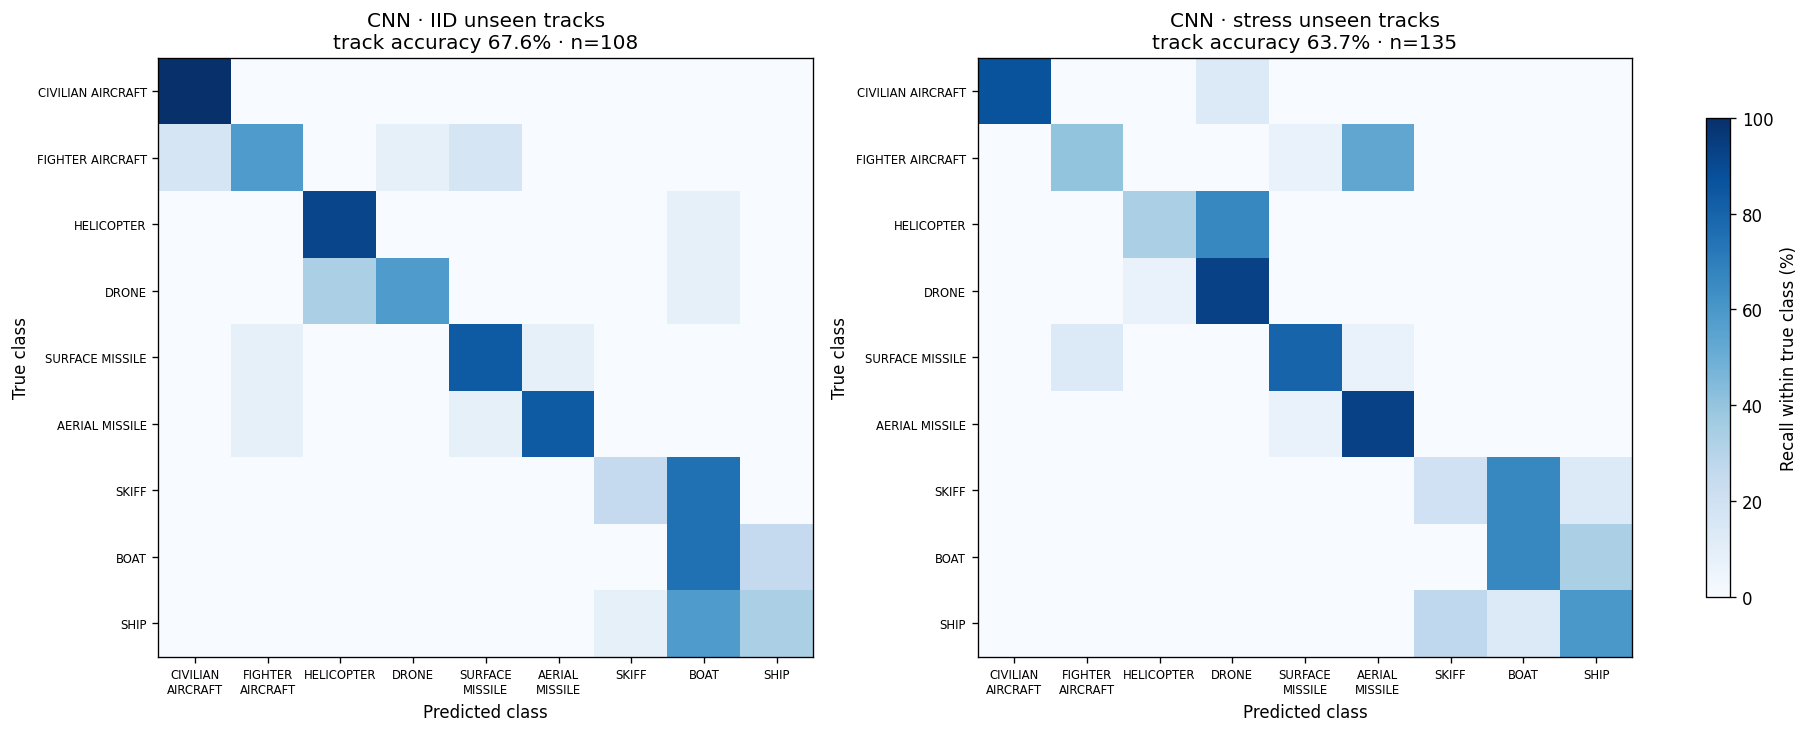

In [7]:
# Evaluate at physical-track level. Window metrics are supporting metrics only.
val_probs = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
iid_probs = model.predict(X_iid_test, batch_size=BATCH_SIZE, verbose=0)
stress_probs = model.predict(X_stress_test, batch_size=BATCH_SIZE, verbose=0)

def track_level_results(probs, meta):
    rows = []
    temp = meta.reset_index(drop=True).copy()
    for tid, idx in temp.groupby("track_no", sort=False).groups.items():
        ix = np.asarray(list(idx), dtype=int)
        p = probs[ix].mean(axis=0)
        rows.append({
            "track_no": tid,
            "true_class": str(temp.loc[ix[0], "true_class"]),
            "predicted_class": str(label_encoder.inverse_transform([int(np.argmax(p))])[0]),
            "mean_model_score_not_calibrated": float(np.max(p)),
            "n_windows": len(ix),
        })
    return pd.DataFrame(rows)

cnn_val_results = track_level_results(val_probs, meta_val)
iid_track_results = track_level_results(iid_probs, meta_iid_test)
stress_track_results = track_level_results(stress_probs, meta_stress_test)

def metric_row(model_name, split_name, results):
    yt = results["true_class"]
    yp = results["predicted_class"]
    return {
        "model": model_name, "split": split_name,
        "track_accuracy": float(accuracy_score(yt, yp)),
        "macro_f1": float(f1_score(yt, yp, labels=CLASSES, average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(yt, yp)),
        "n_tracks": int(len(results)),
    }

cnn_metrics = pd.DataFrame([
    metric_row("CNN-BiGRU-attention", "validation", cnn_val_results),
    metric_row("CNN-BiGRU-attention", "IID test", iid_track_results),
    metric_row("CNN-BiGRU-attention", "stress test", stress_track_results),
])
print("CNN synthetic track-level evaluation (not real-radar accuracy):")
display(cnn_metrics.style.format({"track_accuracy":"{:.1%}", "macro_f1":"{:.3f}", "balanced_accuracy":"{:.1%}"}))

# One combined IID/stress confusion-matrix figure; plots are not redrawn per packet.
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120, constrained_layout=True)
for ax, results, title in [(axes[0], iid_track_results, "CNN · IID unseen tracks"),
                           (axes[1], stress_track_results, "CNN · stress unseen tracks")]:
    cm = confusion_matrix(results["true_class"], results["predicted_class"], labels=CLASSES)
    support = cm.sum(axis=1)
    pct = np.divide(cm, support[:, None], out=np.zeros_like(cm, dtype=float), where=support[:, None] != 0) * 100
    im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(CLASSES)), [c.replace("_", "\n") for c in CLASSES], rotation=0, fontsize=7)
    ax.set_yticks(range(len(CLASSES)), [c.replace("_", " ") for c in CLASSES], fontsize=7)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    acc = accuracy_score(results["true_class"], results["predicted_class"])
    ax.set_title(f"{title}\ntrack accuracy {acc:.1%} · n={len(results)}")
fig.colorbar(im, ax=axes, shrink=0.8, label="Recall within true class (%)")
plt.show()


## 6. Train ExtraTrees track-summary baseline

In [8]:
# ExtraTrees was the strongest Model-21 baseline in prior runs. Train it on the SAME
# physical track split used above. No labels/IDs/scenario metadata enter its predictors.
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report

TRACK_SUMMARY_STATS = ("median", "q10", "q90", "std", "delta")

def summarize_labeled_track(g):
    g = g.sort_values("ntp_sec", kind="stable").tail(SEQUENCE_LENGTH)
    row = {
        "track_no": g["track_no"].iloc[0],
        "true_class": str(g["_true_class"].iloc[0]),
        "scenario_family": str(g["_scenario_family"].iloc[0]),
        "n_packets_used": int(len(g)),
    }
    for col in FEATURE_COLS:
        arr = pd.to_numeric(g[col], errors="coerce").replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
        valid = arr[np.isfinite(arr)]
        if len(valid) == 0:
            vals = {"median": np.nan, "q10": np.nan, "q90": np.nan, "std": np.nan, "delta": np.nan}
        else:
            vals = {
                "median": float(np.nanmedian(valid)),
                "q10": float(np.nanquantile(valid, 0.10)),
                "q90": float(np.nanquantile(valid, 0.90)),
                "std": float(np.nanstd(valid, ddof=0)),
                "delta": float(valid[-1] - valid[0]) if len(valid) >= 2 else 0.0,
            }
        for stat, value in vals.items():
            row[f"{col}__{stat}"] = value
    return row

track_summary_df = pd.DataFrame([
    summarize_labeled_track(g) for _, g in sim_features.groupby("track_no", sort=False)
])
TRACK_SUMMARY_COLS = [c for c in track_summary_df.columns
                       if c not in {"track_no", "true_class", "scenario_family", "n_packets_used"}]
assert len(TRACK_SUMMARY_COLS) == len(FEATURE_COLS) * len(TRACK_SUMMARY_STATS)
assert track_summary_df["track_no"].is_unique

train_tab = track_summary_df[track_summary_df["track_no"].isin(train_ids)].copy()
val_tab = track_summary_df[track_summary_df["track_no"].isin(val_ids)].copy()
iid_tab = track_summary_df[track_summary_df["track_no"].isin(iid_test_ids)].copy()
stress_tab = track_summary_df[track_summary_df["track_no"].isin(stress_test_ids)].copy()
assert set(train_tab.track_no).isdisjoint(set(val_tab.track_no))
assert set(train_tab.track_no).isdisjoint(set(iid_tab.track_no))
assert set(train_tab.track_no).isdisjoint(set(stress_tab.track_no))

selected_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesClassifier(
        n_estimators=400, min_samples_leaf=2, max_features=0.7,
        class_weight="balanced", n_jobs=-1, random_state=SEED
    )),
])
selected_baseline.fit(train_tab[TRACK_SUMMARY_COLS], train_tab["true_class"])

def predict_tab(tab):
    out = tab[["track_no", "true_class"]].copy()
    out["predicted_class"] = selected_baseline.predict(tab[TRACK_SUMMARY_COLS])
    out["top_score_not_calibrated"] = selected_baseline.predict_proba(tab[TRACK_SUMMARY_COLS]).max(axis=1)
    return out

et_val_results = predict_tab(val_tab)
et_iid_results = predict_tab(iid_tab)
et_stress_results = predict_tab(stress_tab)

et_metrics = pd.DataFrame([
    metric_row("ExtraTrees track-summary", "validation", et_val_results),
    metric_row("ExtraTrees track-summary", "IID test", et_iid_results),
    metric_row("ExtraTrees track-summary", "stress test", et_stress_results),
])
synthetic_metrics = pd.concat([cnn_metrics, et_metrics], ignore_index=True)
print("\nCNN vs ExtraTrees — same synthetic physical-track splits:")
display(synthetic_metrics.style.format({"track_accuracy":"{:.1%}", "macro_f1":"{:.3f}", "balanced_accuracy":"{:.1%}"}))
print("\nExtraTrees per-class report — IID test:")
print(classification_report(et_iid_results["true_class"], et_iid_results["predicted_class"], labels=CLASSES, zero_division=0, digits=3))
print("\nExtraTrees per-class report — stress test:")
print(classification_report(et_stress_results["true_class"], et_stress_results["predicted_class"], labels=CLASSES, zero_division=0, digits=3))
print("Reminder: these are synthetic-only metrics. ExtraTrees is an additional candidate; it does not replace the CNN replay.")



CNN vs ExtraTrees — same synthetic physical-track splits:


,model,split,track_accuracy,macro_f1,balanced_accuracy,n_tracks
0,CNN-BiGRU-attention,validation,64.8%,0.633,64.8%,108
1,CNN-BiGRU-attention,IID test,67.6%,0.670,67.6%,108
2,CNN-BiGRU-attention,stress test,63.7%,0.619,63.7%,135
3,ExtraTrees track-summary,validation,84.3%,0.831,84.3%,108
4,ExtraTrees track-summary,IID test,75.9%,0.755,75.9%,108
5,ExtraTrees track-summary,stress test,80.0%,0.795,80.0%,135



ExtraTrees per-class report — IID test:
                   precision    recall  f1-score   support

CIVILIAN_AIRCRAFT      0.857     1.000     0.923        12
 FIGHTER_AIRCRAFT      0.875     0.583     0.700        12
       HELICOPTER      0.706     1.000     0.828        12
            DRONE      0.875     0.583     0.700        12
  SURFACE_MISSILE      0.786     0.917     0.846        12
   AERIAL_MISSILE      1.000     0.917     0.957        12
            SKIFF      0.636     0.583     0.609        12
             BOAT      0.462     0.500     0.480        12
             SHIP      0.750     0.750     0.750        12

         accuracy                          0.759       108
        macro avg      0.772     0.759     0.755       108
     weighted avg      0.772     0.759     0.755       108


ExtraTrees per-class report — stress test:
                   precision    recall  f1-score   support

CIVILIAN_AIRCRAFT      1.000     0.933     0.966        15
 FIGHTER_AIRCRAFT      0.8

## 7. Upload real radar CSV (unlabelled inference only)

In [9]:
# Fresh runtime: explicitly upload the REAL, unlabelled radar CSV for inference.
try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No CSV uploaded. Upload radar_data.csv and rerun this cell.")
    CSV_PATH = Path(next(iter(uploaded.keys())))
except ImportError:
    CSV_PATH = Path(input("Enter path to the real radar CSV: ").strip().strip('"'))
if not CSV_PATH.exists():
    raise FileNotFoundError(f"CSV not found: {CSV_PATH}")
# sep=None lets pandas infer comma-delimited CSV or tab-delimited pasted text files.
raw_csv = pd.read_csv(CSV_PATH, sep=None, engine="python")
if len(raw_csv.columns) == 1 and isinstance(raw_csv.columns[0], str) and "\t" in raw_csv.columns[0]:
    # Defensive fallback for text pasted with literal tab separators.
    raw_csv = pd.read_csv(CSV_PATH, sep="\t")
if "track_no" not in raw_csv.columns:
    raw_csv["track_no"] = 1
if "ntp_sec" not in raw_csv.columns:
    raw_csv["ntp_sec"] = np.arange(len(raw_csv), dtype=float) * SAMPLE_SECONDS
raw_csv = raw_csv.dropna(subset=["track_no", "ntp_sec"]).copy().reset_index(drop=True)
# Stable row ID lets us compute each track's causal rolling/cumulative features once,
# then replay those rows in global timestamp order without mixing track histories.
raw_csv["_packet_id"] = np.arange(len(raw_csv), dtype=np.int64)
print("CSV:", CSV_PATH, "| rows:", len(raw_csv), "| tracks:", raw_csv.track_no.nunique())
print("Target labels from CSV used: NO")
print("\nCoordinate audit before any mapping:")
coordinate_report = coordinate_frame_audit(raw_csv)
if CONFIRM_VELOCITY_ACCEL_XY_SWAP:
    # Explicitly opt in only after checking the ICD. Never infer this mapping from correlation alone.
    for a, b in [("vel_x", "vel_y"), ("accel_x", "accel_y"),
                 ("std_dev_vx", "std_dev_vy"), ("std_dev_ax", "std_dev_ay")]:
        if a in raw_csv.columns and b in raw_csv.columns:
            raw_csv[[a, b]] = raw_csv[[b, a]].to_numpy()
    print("⚠️ Applied the explicitly configured X/Y velocity/acceleration swap. Verify against ICD documentation.")
    coordinate_report = coordinate_frame_audit(raw_csv)
coordinate_mapping_suspect = False
if not coordinate_report.empty and {"reported_velocity_axis", "corr_with_dpos_x", "corr_with_dpos_y"}.issubset(coordinate_report.columns):
    rx = coordinate_report[coordinate_report["reported_velocity_axis"] == "x"]
    ry = coordinate_report[coordinate_report["reported_velocity_axis"] == "y"]
    if len(rx) and len(ry):
        rx, ry = rx.iloc[0], ry.iloc[0]
        coordinate_mapping_suspect = bool(
            (pd.notna(rx["corr_with_dpos_y"]) and (pd.isna(rx["corr_with_dpos_x"]) or rx["corr_with_dpos_y"] > rx["corr_with_dpos_x"] + 0.25))
            or (pd.notna(ry["corr_with_dpos_x"]) and (pd.isna(ry["corr_with_dpos_y"]) or ry["corr_with_dpos_x"] > ry["corr_with_dpos_y"] + 0.25))
        )
if coordinate_mapping_suspect and not CONFIRM_VELOCITY_ACCEL_XY_SWAP:
    print("⚠️ Classification status will include VERIFY ICD AXES until the coordinate convention is confirmed.")
unc_present = [c for c in UNCERTAINTY_COLS if c in raw_csv.columns]
if unc_present:
    print(f"Uncertainty/covariance columns present: {len(unc_present)}; retained for diagnostics only.")
real_features = robust_feature_extractor(raw_csv)

real_matrix = imputer.transform(real_features[FEATURE_COLS])
real_scaled_array = np.clip(scaler.transform(real_matrix), -8, 8)
shift_share = np.mean(np.abs(real_scaled_array) > 5.0, axis=0)
shift_report = pd.Series(shift_share, index=FEATURE_COLS).sort_values(ascending=False)
print("\nFeatures with >10% of rows beyond 5 robust-scaler units (diagnostic, not a verdict):")
print(shift_report[shift_report > 0.10].to_string() if (shift_report > 0.10).any() else "None detected by this simple check.")
print("⚠️ No outlier warning does NOT prove the real data matches synthetic training or that model scores are calibrated.")

Saving radar_data.csv to radar_data.csv
CSV: radar_data.csv | rows: 82 | tracks: 1
Target labels from CSV used: NO

Coordinate audit before any mapping:
Position/velocity axis audit (diagnostic only; no automatic axis swapping):


,reported_velocity_axis,corr_with_dpos_x,corr_with_dpos_y,corr_with_dpos_z
0,x,-0.024,0.998,-0.027
1,y,0.997,0.035,-0.030
2,z,0.105,0.053,0.593


⚠️ vel_x aligns more with d(pos_y) than d(pos_x). Verify the ICD axis convention before using signed axis features.
⚠️ vel_y aligns more with d(pos_x) than d(pos_y). Verify the ICD axis convention before using signed axis features.
⚠️ Classification status will include VERIFY ICD AXES until the coordinate convention is confirmed.
Uncertainty/covariance columns present: 12; retained for diagnostics only.

Features with >10% of rows beyond 5 robust-scaler units (diagnostic, not a verdict):
None detected by this simple check.
⚠️ No outlier warning does NOT prove the real data matches synthetic training or that model scores are calibrated.


## 8. Model-11-style append-only packet replay (plots only after replay)

In [10]:
# 7. LIVE FEED — append-only packet-by-packet replay (NO blinking dashboard/plots)
import time
from collections import deque

EMA_ALPHA = 0.12                  # score smoothing for display; not probability calibration
MIN_STABLE_STREAK = 3
LIVE_HISTORY_POINTS = 240
FOCUS_TRACK = None                # None = track with most packets; or specify an exact track_no

class_order = list(label_encoder.classes_)
feature_lookup = real_features.set_index("_packet_id", drop=False)
scaled_lookup = {int(pid): np.asarray(vec, dtype=np.float32)
                 for pid, vec in zip(real_features["_packet_id"].astype(int), real_scaled_array)}
ordered = raw_csv.sort_values("ntp_sec", kind="stable").reset_index(drop=True)
track_packet_counts = ordered.groupby("track_no", sort=False).size()
if FOCUS_TRACK is None:
    focus_track = track_packet_counts.idxmax()
else:
    if FOCUS_TRACK not in set(ordered["track_no"].tolist()):
        raise ValueError(f"FOCUS_TRACK={FOCUS_TRACK!r} not found in CSV track_no values")
    focus_track = FOCUS_TRACK

stream_rows = []
track_states = {}
print("📡 LIVE RADAR REPLAY — append-only feed; plots are deferred until the end", flush=True)
print(f"File: {CSV_PATH} | packets: {len(ordered)} | tracks: {ordered['track_no'].nunique()} | focus track: {focus_track}", flush=True)
print("Scores are uncalibrated synthetic-model scores; input CSV labels are never used.\n", flush=True)

for packet_idx, packet in ordered.iterrows():
    tid = packet["track_no"]
    packet_id = int(packet["_packet_id"])
    scaled_row = scaled_lookup[packet_id]
    feat_row = feature_lookup.loc[packet_id]

    state = track_states.get(tid)
    if state is None:
        state = {
            "scaled_window": deque(maxlen=SEQUENCE_LENGTH),
            "history": deque(maxlen=LIVE_HISTORY_POINTS),
            "ema": None, "count": 0, "candidate": None, "candidate_streak": 0,
            "stable": "WARMING_UP", "last_seen": float(packet["ntp_sec"]),
            "last_window_candidate": "WARMING_UP", "last_window_score": np.nan,
            "last_track_candidate": "WARMING_UP", "last_track_score": np.nan,
            "last_margin": np.nan, "last_status": "PROVISIONAL — SHORT HISTORY",
            "last_speed": np.nan, "last_altitude": np.nan, "last_accel": np.nan,
        }

    # Each track has its own sequence buffer. Interleaved tracks never share packets.
    state["scaled_window"].append(scaled_row)
    available = np.asarray(state["scaled_window"], dtype=np.float32)
    warmup = state["count"] + 1 < SEQUENCE_LENGTH
    if len(available) < SEQUENCE_LENGTH:
        sequence = np.concatenate([np.repeat(available[:1], SEQUENCE_LENGTH-len(available), axis=0), available], axis=0)
    else:
        sequence = available[-SEQUENCE_LENGTH:]

    p = np.asarray(model.predict(sequence[None, ...], verbose=0)[0], dtype=float)
    p = np.clip(p, 1e-8, 1.0); p /= p.sum()
    window_idx = int(np.argmax(p))
    window_candidate = class_order[window_idx]
    window_score = float(p[window_idx])
    if state["ema"] is None:
        state["ema"] = p.copy()
    else:
        state["ema"] = (1.0-EMA_ALPHA)*state["ema"] + EMA_ALPHA*p
        state["ema"] /= state["ema"].sum()
    track_p = state["ema"].copy()
    rank = np.argsort(track_p)[::-1]
    track_idx = int(rank[0]); track_candidate = class_order[track_idx]
    track_score = float(track_p[track_idx])
    margin = float(track_p[rank[0]] - track_p[rank[1]])

    if track_candidate == state["candidate"]:
        state["candidate_streak"] += 1
    else:
        state["candidate"] = track_candidate
        state["candidate_streak"] = 1
    if not warmup and state["candidate_streak"] >= MIN_STABLE_STREAK and track_score >= 0.40 and margin >= 0.08:
        state["stable"] = track_candidate

    if warmup:
        status = "PROVISIONAL — SHORT HISTORY"
    elif track_score < 0.40 or margin < 0.08:
        status = "LOW / AMBIGUOUS MODEL EVIDENCE"
    elif coordinate_mapping_suspect and not CONFIRM_VELOCITY_ACCEL_XY_SWAP:
        status = "CANDIDATE — VERIFY ICD AXES"
    else:
        status = "SYNTHETIC-MODEL CANDIDATE — UNVERIFIED"

    getnum = lambda col: float(feat_row[col]) if col in feat_row.index and pd.notna(feat_row[col]) else np.nan
    speed, altitude, acceleration = getnum("vel_mag"), getnum("pos_z"), getnum("accel_mag")
    state["count"] += 1
    state["last_seen"] = float(packet["ntp_sec"])
    state["last_window_candidate"] = window_candidate
    state["last_window_score"] = window_score
    state["last_track_candidate"] = track_candidate
    state["last_track_score"] = track_score
    state["last_margin"] = margin
    state["last_status"] = status
    state["last_speed"] = speed; state["last_altitude"] = altitude; state["last_accel"] = acceleration
    hist_row = {
        "ntp_sec": float(packet["ntp_sec"]), "window_candidate": window_candidate,
        "window_score": window_score, "track_candidate": track_candidate,
        "track_score": track_score, "stable_hypothesis": state["stable"],
        "speed": speed, "altitude": altitude, "acceleration": acceleration,
    }
    hist_row.update({f"track_score_{c}": float(track_p[j]) for j, c in enumerate(class_order)})
    state["history"].append(hist_row)
    track_states[tid] = state

    row = {
        "track_no": tid, "ntp_sec": float(packet["ntp_sec"]),
        "packet_index_global": packet_idx+1, "packet_index_for_track": state["count"],
        "window_candidate": window_candidate, "window_score_not_calibrated": window_score,
        "track_candidate": track_candidate, "track_score_not_calibrated": track_score,
        "top2_margin_not_calibrated": margin, "stable_hypothesis": state["stable"],
        "status": status, "warmup": warmup, "speed": speed, "altitude": altitude,
        "acceleration": acceleration, "coordinate_mapping_suspect": coordinate_mapping_suspect,
        "ground_truth": "UNLABELLED — not available",
    }
    for j, c in enumerate(class_order):
        row[f"window_score_{c}"] = float(p[j])
        row[f"track_score_{c}"] = float(track_p[j])
    stream_rows.append(row)

    # Crucially: plain print only. No clear_output, dashboard redraw, display(), or plotting here.
    if PRINT_EVERY_N_PACKETS > 0 and ((packet_idx+1) % PRINT_EVERY_N_PACKETS == 0):
        print(f"📡 packet {packet_idx+1:>5}/{len(ordered)} | t={packet['ntp_sec']} | track={tid} | "
              f"window={window_candidate} ({window_score:.1%}) | track={track_candidate} ({track_score:.1%}) | "
              f"stable={state['stable']} | {status}", flush=True)
        if PLAYBACK_DELAY > 0:
            time.sleep(PLAYBACK_DELAY)

stream = pd.DataFrame(stream_rows).sort_values("ntp_sec", kind="stable").reset_index(drop=True)

# Integrity checks: every input packet appears exactly once, and per-track counts are unchanged.
assert len(stream) == len(raw_csv), f"Output rows ({len(stream)}) != input packets ({len(raw_csv)})"
input_counts = raw_csv.groupby("track_no", sort=False).size().to_dict()
output_counts = stream.groupby("track_no", sort=False).size().to_dict()
assert input_counts == output_counts, "Per-track packet counts changed during replay"
assert stream.groupby("track_no")["packet_index_for_track"].max().to_dict() == input_counts
print("\n✅ Multi-track integrity checks passed.", flush=True)
print(f"✅ Replay integrity passed: {len(stream)} input packets -> {len(stream)} packet predictions", flush=True)

📡 LIVE RADAR REPLAY — append-only feed; plots are deferred until the end
File: radar_data.csv | packets: 82 | tracks: 1 | focus track: 1
Scores are uncalibrated synthetic-model scores; input CSV labels are never used.

📡 packet     1/82 | t=3991182426.0 | track=1.0 | window=AERIAL_MISSILE (48.8%) | track=AERIAL_MISSILE (48.8%) | stable=WARMING_UP | PROVISIONAL — SHORT HISTORY
📡 packet     2/82 | t=3991182434.0 | track=1.0 | window=AERIAL_MISSILE (51.5%) | track=AERIAL_MISSILE (49.1%) | stable=WARMING_UP | PROVISIONAL — SHORT HISTORY
📡 packet     3/82 | t=3991182444.0 | track=1.0 | window=AERIAL_MISSILE (55.7%) | track=AERIAL_MISSILE (49.9%) | stable=WARMING_UP | PROVISIONAL — SHORT HISTORY
📡 packet     4/82 | t=3991182454.0 | track=1.0 | window=AERIAL_MISSILE (49.4%) | track=AERIAL_MISSILE (49.8%) | stable=WARMING_UP | PROVISIONAL — SHORT HISTORY
📡 packet     5/82 | t=3991182464.0 | track=1.0 | window=AERIAL_MISSILE (43.1%) | track=AERIAL_MISSILE (49.0%) | stable=WARMING_UP | PROVISION

## 9. Final combined track candidates and one results workbook

In [11]:
# Final track-level candidates: CNN packet replay + ExtraTrees summary model.
# ExtraTrees uses precisely the same final-30-packet summary definitions as synthetic training.

def summarize_unlabelled_track(g):
    g = g.sort_values("ntp_sec", kind="stable").tail(SEQUENCE_LENGTH)
    row = {"track_no": g["track_no"].iloc[0], "n_packets_used": int(len(g))}
    for col in FEATURE_COLS:
        arr = pd.to_numeric(g[col], errors="coerce").replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
        valid = arr[np.isfinite(arr)]
        if len(valid) == 0:
            vals = {"median": np.nan, "q10": np.nan, "q90": np.nan, "std": np.nan, "delta": np.nan}
        else:
            vals = {
                "median": float(np.nanmedian(valid)),
                "q10": float(np.nanquantile(valid, 0.10)),
                "q90": float(np.nanquantile(valid, 0.90)),
                "std": float(np.nanstd(valid, ddof=0)),
                "delta": float(valid[-1] - valid[0]) if len(valid) >= 2 else 0.0,
            }
        for stat, value in vals.items():
            row[f"{col}__{stat}"] = value
    return row

real_summary_df = pd.DataFrame([
    summarize_unlabelled_track(g) for _, g in real_features.groupby("track_no", sort=False)
])
X_real_et = real_summary_df.reindex(columns=["track_no"] + TRACK_SUMMARY_COLS).copy()
X_real_et[TRACK_SUMMARY_COLS] = X_real_et[TRACK_SUMMARY_COLS].apply(pd.to_numeric, errors="coerce")
et_pred = selected_baseline.predict(X_real_et[TRACK_SUMMARY_COLS])
et_prob = selected_baseline.predict_proba(X_real_et[TRACK_SUMMARY_COLS])
et_classes = np.asarray(selected_baseline.named_steps["model"].classes_, dtype=str)

def topk_row(prob, classes, k=3):
    ix = np.argsort(prob)[::-1][:k]
    out = {}
    for r, j in enumerate(ix, start=1):
        out[f"ExtraTrees_candidate_{r}"] = str(classes[j])
        out[f"ExtraTrees_score_{r}_not_calibrated"] = float(prob[j])
    return out

et_real_rows = []
for i, row in X_real_et.iterrows():
    item = {"track_no": row["track_no"], "ExtraTrees_track_candidate": str(et_pred[i]),
            "ExtraTrees_top_score_not_calibrated": float(np.max(et_prob[i]))}
    item.update(topk_row(et_prob[i], et_classes))
    et_real_rows.append(item)
et_real_summary = pd.DataFrame(et_real_rows)

# Build the CNN track summary from the completed replay (one row per physical track).
summary_rows = []
for tid, g in stream.groupby("track_no", sort=False):
    g = g.sort_values("ntp_sec", kind="stable")
    last = g.iloc[-1]
    valid = g[~g["warmup"]]
    changes = int((valid["window_candidate"] != valid["window_candidate"].shift()).sum() - 1) if len(valid) else 0
    score_cols = [f"track_score_{c}" for c in class_order]
    top = last[score_cols].astype(float).sort_values(ascending=False)
    summary_rows.append({
        "track_no": tid, "packets_processed": len(g),
        "first_timestamp": g["ntp_sec"].iloc[0], "last_timestamp": last["ntp_sec"],
        "latest_window_candidate": last["window_candidate"],
        "final_track_candidate": last["track_candidate"],
        "final_stable_hypothesis": last["stable_hypothesis"],
        "top_model_score_not_calibrated": float(top.iloc[0]),
        "runner_up_class": str(top.index[1].replace("track_score_", "")),
        "runner_up_score_not_calibrated": float(top.iloc[1]),
        "window_candidate_changes": max(0, changes), "status": last["status"],
        "ground_truth": "UNLABELLED — not available",
    })
track_summary = pd.DataFrame(summary_rows).sort_values("track_no", key=lambda s: s.astype(str), kind="stable")

# CNN summary was created after append-only replay. Merge by track identifier, never by row order.
final_results = track_summary.merge(et_real_summary, on="track_no", how="left", validate="one_to_one")
final_results["CNN_and_ExtraTrees_agree"] = (
    final_results["final_track_candidate"].astype(str) == final_results["ExtraTrees_track_candidate"].astype(str)
)

def final_status(r):
    if int(r["packets_processed"]) < SEQUENCE_LENGTH:
        return "LOW HISTORY — fewer than 30 packets"
    if coordinate_mapping_suspect and not CONFIRM_VELOCITY_ACCEL_XY_SWAP:
        return "VERIFY ICD AXES — candidates unverified"
    if "LOW / AMBIGUOUS" in str(r["status"]):
        return "LOW / AMBIGUOUS MODEL EVIDENCE"
    if bool(r["CNN_and_ExtraTrees_agree"]):
        return "MODEL AGREEMENT — STILL UNVERIFIED"
    return "MODEL DISAGREEMENT — REVIEW"

final_results["combined_status"] = final_results.apply(final_status, axis=1)
final_results["ground_truth"] = "UNLABELLED — not available"

# One compact status table in notebook output.
visible_cols = [
    "track_no", "packets_processed", "final_track_candidate", "final_stable_hypothesis",
    "top_model_score_not_calibrated", "ExtraTrees_track_candidate",
    "ExtraTrees_top_score_not_calibrated", "CNN_and_ExtraTrees_agree", "combined_status"
]
print("\nFINAL RADAR TRACK CANDIDATES — candidates only, not verified identities")
display(final_results[[c for c in visible_cols if c in final_results.columns]].sort_values("track_no", key=lambda s: s.astype(str)).reset_index(drop=True))

# Per-class metrics for synthetic tests, stored as one worksheet rather than separate CSV files.
per_class_rows = []
for model_name, split_name, df in [
    ("CNN-BiGRU-attention", "validation", cnn_val_results),
    ("CNN-BiGRU-attention", "IID test", iid_track_results),
    ("CNN-BiGRU-attention", "stress test", stress_track_results),
    ("ExtraTrees track-summary", "validation", et_val_results),
    ("ExtraTrees track-summary", "IID test", et_iid_results),
    ("ExtraTrees track-summary", "stress test", et_stress_results),
]:
    rep = classification_report(df["true_class"], df["predicted_class"], labels=CLASSES,
                               output_dict=True, zero_division=0)
    for cls in CLASSES:
        per_class_rows.append({"model": model_name, "split": split_name, "class": cls,
                               "precision": rep[cls]["precision"], "recall": rep[cls]["recall"],
                               "f1": rep[cls]["f1-score"], "support": rep[cls]["support"]})
per_class_metrics = pd.DataFrame(per_class_rows)

# Save one workbook, not a pile of CSVs. No model bundle/ZIP is created.
RESULTS_FILE = Path("radar_final_results.xlsx")
with pd.ExcelWriter(RESULTS_FILE, engine="openpyxl") as writer:
    final_results.to_excel(writer, sheet_name="Track Results", index=False)
    stream.to_excel(writer, sheet_name="Packet Replay", index=False)
    synthetic_metrics.to_excel(writer, sheet_name="Synthetic Evaluation", index=False)
    per_class_metrics.to_excel(writer, sheet_name="Per-class Metrics", index=False)

print(f"\n✅ Saved ONE results workbook: {RESULTS_FILE.resolve()}")
print("Sheets: Track Results | Packet Replay | Synthetic Evaluation | Per-class Metrics")
print("No CSV files or ZIP bundle were generated. Models were trained in memory for this runtime.")
print("Important: all model scores are uncalibrated and the real input has no verified labels; never treat candidates as confirmed identities.")
try:
    from google.colab import files
    files.download(str(RESULTS_FILE))
except Exception:
    print("Automatic Colab download unavailable here; retrieve radar_final_results.xlsx from the current working directory.")



FINAL RADAR TRACK CANDIDATES — candidates only, not verified identities


,track_no,packets_processed,final_track_candidate,final_stable_hypothesis,top_model_score_not_calibrated,ExtraTrees_track_candidate,ExtraTrees_top_score_not_calibrated,CNN_and_ExtraTrees_agree,combined_status
0,1.0,82,FIGHTER_AIRCRAFT,FIGHTER_AIRCRAFT,0.469661,FIGHTER_AIRCRAFT,0.427917,True,VERIFY ICD AXES — candidates unverified



✅ Saved ONE results workbook: /content/radar_final_results.xlsx
Sheets: Track Results | Packet Replay | Synthetic Evaluation | Per-class Metrics
No CSV files or ZIP bundle were generated. Models were trained in memory for this runtime.
Important: all model scores are uncalibrated and the real input has no verified labels; never treat candidates as confirmed identities.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# ============================================================
# FINAL COMPARISON: CNN vs ExtraTrees — REAL RADAR TRACKS
# Run AFTER all previous notebook cells have finished.
# No retraining. No new CSV files.
# ============================================================

import pandas as pd
from IPython.display import display

if "final_results" not in globals():
    raise RuntimeError(
        "The prediction results are not in memory. "
        "Run the notebook from the beginning, then run this cell."
    )

# Show the most useful columns, if available.
columns = [
    "track_no",
    "packets_processed",
    "final_track_candidate",
    "top_model_score_not_calibrated",
    "runner_up_class",
    "runner_up_score_not_calibrated",
    "ExtraTrees_track_candidate",
    "ExtraTrees_top_score_not_calibrated",
    "ExtraTrees_candidate_2",
    "ExtraTrees_score_2_not_calibrated",
    "ExtraTrees_candidate_3",
    "ExtraTrees_score_3_not_calibrated",
    "CNN_and_ExtraTrees_agree",
    "combined_status",
]

available = [c for c in columns if c in final_results.columns]
comparison = final_results[available].copy()

# Give the columns clearer names for reading.
comparison = comparison.rename(columns={
    "final_track_candidate": "CNN prediction",
    "top_model_score_not_calibrated": "CNN top score (uncalibrated)",
    "runner_up_class": "CNN runner-up",
    "runner_up_score_not_calibrated": "CNN runner-up score",
    "ExtraTrees_track_candidate": "ExtraTrees prediction",
    "ExtraTrees_top_score_not_calibrated": "ExtraTrees top score (uncalibrated)",
    "ExtraTrees_candidate_2": "ExtraTrees candidate 2",
    "ExtraTrees_score_2_not_calibrated": "Candidate 2 score",
    "ExtraTrees_candidate_3": "ExtraTrees candidate 3",
    "ExtraTrees_score_3_not_calibrated": "Candidate 3 score",
    "CNN_and_ExtraTrees_agree": "Models agree?",
    "combined_status": "Status",
    "track_no": "Track",
    "packets_processed": "Packets",
})

score_columns = [
    c for c in comparison.columns
    if "score" in c.lower()
]

# Display model scores as percentages, explicitly NOT probabilities.
formatters = {c: (lambda x: f"{x:.1%}" if pd.notna(x) else "—")
              for c in score_columns}

print("📡 CNN vs ExtraTrees — REAL TRACK PREDICTIONS")
print("Scores are uncalibrated; they are NOT probabilities.")
print("The track labels are candidates, not verified target identities.\n")

display(
    comparison.style
    .format(formatters, na_rep="—")
    .set_properties(**{"text-align": "left"})
)

# Quick agreement summary
if "CNN_and_ExtraTrees_agree" in final_results.columns:
    agree = final_results["CNN_and_ExtraTrees_agree"].fillna(False).astype(bool)
    print(f"\nTracks compared: {len(final_results)}")
    print(f"Models agree: {int(agree.sum())}")
    print(f"Models disagree: {int((~agree).sum())}")

print("\nReminder: verify the radar coordinate convention before relying "
      "on these real-track candidates.")


📡 CNN vs ExtraTrees — REAL TRACK PREDICTIONS
Scores are uncalibrated; they are NOT probabilities.
The track labels are candidates, not verified target identities.



,Track,Packets,CNN prediction,CNN top score (uncalibrated),CNN runner-up,CNN runner-up score,ExtraTrees prediction,ExtraTrees top score (uncalibrated),ExtraTrees candidate 2,Candidate 2 score,ExtraTrees candidate 3,Candidate 3 score,Models agree?,Status
0,1.000000,82,FIGHTER_AIRCRAFT,47.0%,DRONE,20.4%,FIGHTER_AIRCRAFT,42.8%,CIVILIAN_AIRCRAFT,21.0%,DRONE,16.9%,True,VERIFY ICD AXES — candidates unverified



Tracks compared: 1
Models agree: 1
Models disagree: 0

Reminder: verify the radar coordinate convention before relying on these real-track candidates.
